# Global Cybersecurity Threats Analysis (2015–2024)

**Goal:** Analyze 3,000 cybersecurity incidents to understand trends, the most damaging attack types, the most targeted industries and countries, and which defenses are linked to faster resolution.

**Dataset:** [Global Cybersecurity Threats 2015–2024](https://www.kaggle.com/datasets/atharvasoundankar/global-cybersecurity-threats-2015-2024) (Kaggle, CC0 Public Domain)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/Global_Cybersecurity_Threats_2015-2024.csv")
df.head()

,Country,Year,Attack Type,Target Industry,Financial Loss (in Million $),Number of Affected Users,Attack Source,Security Vulnerability Type,Defense Mechanism Used,Incident Resolution Time (in Hours)
0,China,2019,Phishing,Education,80.53,773169,Hacker Group,Unpatched Software,VPN,63
1,China,2019,Ransomware,Retail,62.19,295961,Hacker Group,Unpatched Software,Firewall,71
2,India,2017,Man-in-the-Middle,IT,38.65,605895,Hacker Group,Weak Passwords,VPN,20
3,UK,2024,Ransomware,Telecommunications,41.44,659320,Nation-state,Social Engineering,AI-based Detection,7
4,Germany,2018,Man-in-the-Middle,IT,74.41,810682,Insider,Social Engineering,VPN,68


## 1. Data Exploration

In [2]:
df.shape

(3000, 10)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Country                              3000 non-null   str    
 1   Year                                 3000 non-null   int64  
 2   Attack Type                          3000 non-null   str    
 3   Target Industry                      3000 non-null   str    
 4   Financial Loss (in Million $)        3000 non-null   float64
 5   Number of Affected Users             3000 non-null   int64  
 6   Attack Source                        3000 non-null   str    
 7   Security Vulnerability Type          3000 non-null   str    
 8   Defense Mechanism Used               3000 non-null   str    
 9   Incident Resolution Time (in Hours)  3000 non-null   int64  
dtypes: float64(1), int64(3), str(6)
memory usage: 234.5 KB


In [4]:
df.describe()

,Year,Financial Loss (in Million $),Number of Affected Users,Incident Resolution Time (in Hours)
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,2019.570333,50.492970,504684.136333,36.476000
std,2.857932,28.791415,289944.084972,20.570768
min,2015.000000,0.500000,424.000000,1.000000
25%,2017.000000,25.757500,255805.250000,19.000000
50%,2020.000000,50.795000,504513.000000,37.000000
75%,2022.000000,75.630000,758088.500000,55.000000
max,2024.000000,99.990000,999635.000000,72.000000


In [5]:
df.nunique()

Country                                  10
Year                                     10
Attack Type                               6
Target Industry                           7
Financial Loss (in Million $)          2536
Number of Affected Users               2998
Attack Source                             4
Security Vulnerability Type               4
Defense Mechanism Used                    5
Incident Resolution Time (in Hours)      72
dtype: int64

In [6]:
df.isnull().sum()

Country                                0
Year                                   0
Attack Type                            0
Target Industry                        0
Financial Loss (in Million $)          0
Number of Affected Users               0
Attack Source                          0
Security Vulnerability Type            0
Defense Mechanism Used                 0
Incident Resolution Time (in Hours)    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

### Exploration Summary
- The dataset has **3,000 rows** (incidents) and **10 columns**.
- **Missing values:** none, all columns are complete.
- **Duplicate rows:** none.
- **6 text columns:** Country, Attack Type, Target Industry, Attack Source, Security Vulnerability Type, Defense Mechanism Used.
- **4 numeric columns:** Year, Financial Loss (in Million $), Number of Affected Users, Incident Resolution Time (in Hours).
- **Categories are small:** 10 countries, 6 attack types, 7 industries, 4 attack sources, 4 vulnerability types, 5 defense mechanisms. This makes them suitable for grouping and comparison.
- **Note:** Financial loss (0.5–100M $), affected users and resolution time (1–72 hours) are spread almost perfectly evenly between their min and max. Real incident data is usually skewed (many small incidents, few huge ones), so this dataset is likely **synthetic**. Differences between groups are expected to be small, and findings should be interpreted with care.

## 2. Data Cleaning

**Rename columns:** The original names are long and contain spaces and symbols (e.g. `Financial Loss (in Million $)`). Short snake_case names are easier to type and less error-prone in code.

In [8]:
df = df.rename(columns={
    "Country": "country",
    "Year": "year",
    "Attack Type": "attack_type",
    "Target Industry": "target_industry",
    "Financial Loss (in Million $)": "financial_loss_musd",
    "Number of Affected Users": "affected_users",
    "Attack Source": "attack_source",
    "Security Vulnerability Type": "vulnerability_type",
    "Defense Mechanism Used": "defense_mechanism",
    "Incident Resolution Time (in Hours)": "resolution_hours",
})
df.columns

Index(['country', 'year', 'attack_type', 'target_industry',
       'financial_loss_musd', 'affected_users', 'attack_source',
       'vulnerability_type', 'defense_mechanism', 'resolution_hours'],
      dtype='str')

**Check text columns:** Look at every unique value to catch typos, inconsistent capitalization, or extra spaces (e.g. "UK" vs "uk " would be counted as two countries).

In [9]:
text_cols = ["country", "attack_type", "target_industry",
             "attack_source", "vulnerability_type", "defense_mechanism"]

for col in text_cols:
    print(col, ":", sorted(df[col].unique()))

country : ['Australia', 'Brazil', 'China', 'France', 'Germany', 'India', 'Japan', 'Russia', 'UK', 'USA']
attack_type : ['DDoS', 'Malware', 'Man-in-the-Middle', 'Phishing', 'Ransomware', 'SQL Injection']
target_industry : ['Banking', 'Education', 'Government', 'Healthcare', 'IT', 'Retail', 'Telecommunications']
attack_source : ['Hacker Group', 'Insider', 'Nation-state', 'Unknown']
vulnerability_type : ['Social Engineering', 'Unpatched Software', 'Weak Passwords', 'Zero-day']
defense_mechanism : ['AI-based Detection', 'Antivirus', 'Encryption', 'Firewall', 'VPN']


**Strip whitespace:** No problems were visible, but invisible leading/trailing spaces are a common issue. Stripping them is a safe, defensive step.

In [10]:
for col in text_cols:
    df[col] = df[col].str.strip()

**Convert text columns to `category`:** Each text column has only 4–10 repeated values. The `category` type stores them more efficiently and tells pandas (and the reader) that these are groups, not free text.

In [11]:
for col in text_cols:
    df[col] = df[col].astype("category")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   country              3000 non-null   category
 1   year                 3000 non-null   int64   
 2   attack_type          3000 non-null   category
 3   target_industry      3000 non-null   category
 4   financial_loss_musd  3000 non-null   float64 
 5   affected_users       3000 non-null   int64   
 6   attack_source        3000 non-null   category
 7   vulnerability_type   3000 non-null   category
 8   defense_mechanism    3000 non-null   category
 9   resolution_hours     3000 non-null   int64   
dtypes: category(6), float64(1), int64(3)
memory usage: 111.7 KB


**Check value ranges:** Financial loss, affected users, and resolution time should never be negative or zero, and years should be within 2015–2024.

In [12]:
print("Negative losses:", (df["financial_loss_musd"] < 0).sum())
print("Negative affected users:", (df["affected_users"] < 0).sum())
print("Resolution time <= 0:", (df["resolution_hours"] <= 0).sum())
print("Years:", df["year"].min(), "to", df["year"].max())

Negative losses: 0
Negative affected users: 0
Resolution time <= 0: 0
Years: 2015 to 2024


**Save cleaned dataset:** Saved as a separate file so the raw data stays untouched, and so Project 2 (Interactive Dashboard) can reuse it directly.

In [13]:
df.to_csv("../data/cybersecurity_threats_clean.csv", index=False)

### Cleaning Summary
- Renamed all columns to short snake_case names.
- Checked all text values: no typos or inconsistent labels found; stripped whitespace as a precaution.
- Converted 6 text columns to `category` type (reduced memory usage).
- No missing values or duplicates → no rows removed.
- No negative or impossible values; years range from 2015 to 2024.
- Saved the clean data to `data/cybersecurity_threats_clean.csv`.
- `attack_source` contains an **"Unknown"** category, a hidden missing value. Kept as its own group because the incident itself is still valid; it will be reported separately in the analysis.

## 3. Exploratory Analysis

### Q1. How did the number of incidents and total financial loss change from 2015 to 2024?

In [14]:
yearly = df.groupby("year").agg(
    incidents=("year", "count"),
    total_loss_musd=("financial_loss_musd", "sum"),
).round(1)
yearly

,incidents,total_loss_musd
year,,
2015,277,14510.2
2016,285,13947.3
2017,319,16261.7
2018,310,14720.5
2019,263,13134.7
2020,315,15768.0
2021,299,15873.4
2022,318,15870.9
2023,315,15958.1


**Answer:** Incidents ranged from 263 (2019) to 319 (2017) with no clear upward or downward trend. Total loss closely follows the number of incidents, meaning the average loss per incident stayed stable (~50M $). 2020–2023 were slightly above average.

### Q2. Which attack types cause the highest average financial loss and affect the most users?

In [15]:
by_attack = df.groupby("attack_type", observed=True).agg(
    incidents=("attack_type", "count"),
    avg_loss_musd=("financial_loss_musd", "mean"),
    avg_affected_users=("affected_users", "mean"),
).round(1).sort_values("avg_loss_musd", ascending=False)
by_attack

,incidents,avg_loss_musd,avg_affected_users
attack_type,,,
DDoS,531,52.0,499437.4
Man-in-the-Middle,459,51.3,520064.3
Phishing,529,50.5,487179.5
SQL Injection,503,50.0,512469.8
Ransomware,493,49.7,502825.4
Malware,485,49.4,508780.2


**Answer:** DDoS is the most frequent attack (531) and has the highest average loss (52.0M $), while Malware has the lowest (49.4M $). However, the difference is only ~5%, so no attack type is clearly more damaging. Man-in-the-Middle affects the most users on average (~520K).

### Q3. Which industries are attacked most, and what is the most common attack type in each?

In [16]:
df["target_industry"].value_counts()

target_industry
IT                    478
Banking               445
Healthcare            429
Retail                423
Education             419
Government            403
Telecommunications    403
Name: count, dtype: int64

In [17]:
industry_attack = pd.crosstab(df["target_industry"], df["attack_type"])
industry_attack["most_common_attack"] = industry_attack.idxmax(axis=1)
industry_attack

attack_type,DDoS,Malware,Man-in-the-Middle,Phishing,Ransomware,SQL Injection,most_common_attack
target_industry,,,,,,,
Banking,71,61,77,96,69,71,Phishing
Education,73,70,65,73,71,67,DDoS
Government,71,64,53,68,72,75,SQL Injection
Healthcare,78,81,58,63,77,72,Malware
IT,91,67,80,89,74,77,DDoS
Retail,62,68,70,89,71,63,Phishing
Telecommunications,85,74,56,51,59,78,DDoS


**Answer:** IT is the most targeted industry (478 incidents), followed by Banking (445) and Healthcare (429). The most common attack differs by industry: Phishing in Banking and Retail, DDoS in IT and Telecommunications, Malware in Healthcare, and SQL Injection in Government. Education is a tie between DDoS and Phishing (73 each), and IT is very close (DDoS 91 vs Phishing 89).

### Q4. Which countries had the largest total financial losses?

In [18]:
by_country = (
    df.groupby("country", observed=True)["financial_loss_musd"]
    .sum()
    .sort_values(ascending=False)
    .round(1)
)
by_country

country
UK           16503.0
Germany      15793.2
Brazil       15782.6
Australia    15403.0
Japan        15197.3
France       14972.3
USA          14812.1
Russia       14734.7
India        14566.1
China        13714.5
Name: financial_loss_musd, dtype: float64

**Answer:** The UK had the highest total loss (16.5B $), followed by Germany and Brazil (~15.8B $ each). China had the lowest (13.7B $). Since totals depend on the number of incidents per country, this shows where the most money was lost overall, not that individual attacks were more severe.

### Q5. Which defense mechanisms are linked to the fastest incident resolution?

In [19]:
by_defense = (
    df.groupby("defense_mechanism", observed=True)["resolution_hours"]
    .agg(["mean", "median", "count"])
    .round(1)
    .sort_values("mean")
)
by_defense

,mean,median,count
defense_mechanism,,,
Firewall,35.7,34.0,585
AI-based Detection,36.6,36.0,583
Antivirus,36.6,36.0,628
Encryption,36.6,37.0,592
VPN,36.9,37.5,612


**Answer:** Firewall is linked to the fastest average resolution (35.7 hours) and VPN to the slowest (36.9 hours). The difference is only ~1 hour, so no defense mechanism is meaningfully faster in this dataset. This is a correlation only; it does not prove that a defense causes faster resolution.

## 4. Visualization

In [20]:
sns.set_theme(style="whitegrid")
BLUE = "#2a78d6"

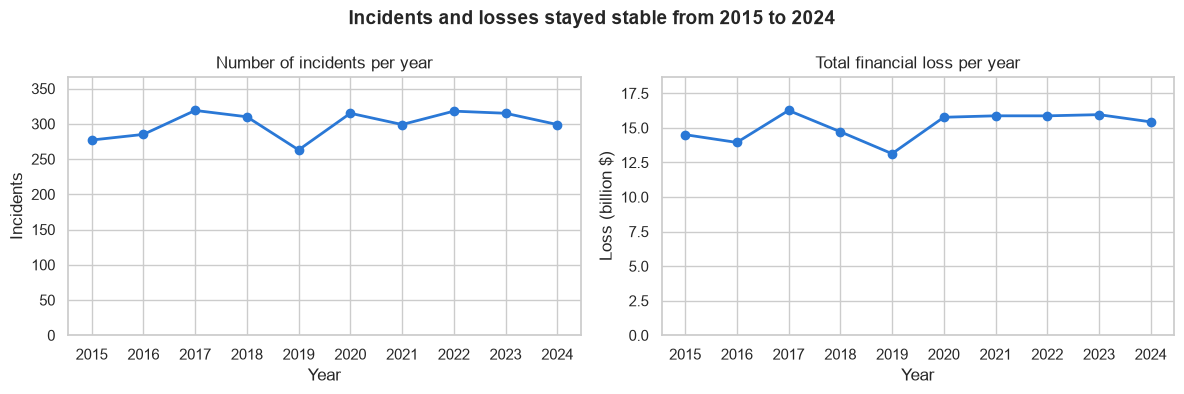

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(yearly.index, yearly["incidents"], marker="o", color=BLUE, linewidth=2)
axes[0].set_title("Number of incidents per year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Incidents")
axes[0].set_ylim(0, yearly["incidents"].max() * 1.15)

axes[1].plot(yearly.index, yearly["total_loss_musd"] / 1000, marker="o", color=BLUE, linewidth=2)
axes[1].set_title("Total financial loss per year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Loss (billion $)")
axes[1].set_ylim(0, yearly["total_loss_musd"].max() / 1000 * 1.15)

for ax in axes:
    ax.set_xticks(yearly.index)

fig.suptitle("Incidents and losses stayed stable from 2015 to 2024", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../images/q1_trend_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Both incidents and losses fluctuate year to year but show no clear long-term trend; total loss rises and falls with the number of incidents.

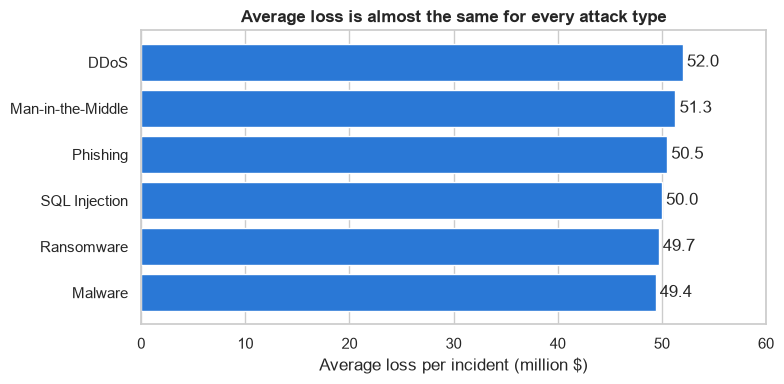

In [26]:
data = by_attack.sort_values("avg_loss_musd")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(data.index.astype(str), data["avg_loss_musd"], color=BLUE)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 60)
ax.set_title("Average loss is almost the same for every attack type", fontweight="bold")
ax.set_xlabel("Average loss per incident (million $)")
plt.tight_layout()
plt.savefig("../images/q2_attack_types.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** DDoS has the highest average loss (52.0M \$), but every attack type falls within 49–52M \$, so attack type alone does not predict how costly an incident will be.

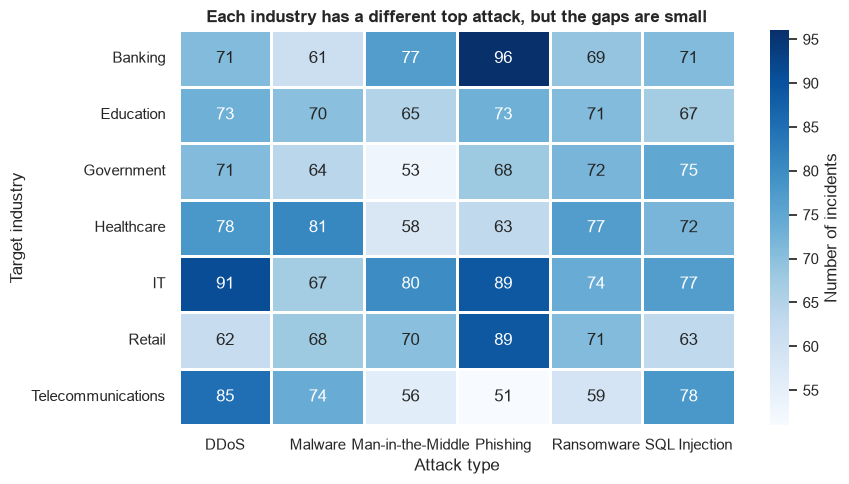

In [23]:
heat = industry_attack.drop(columns="most_common_attack")

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(heat, annot=True, fmt="d", cmap="Blues", linewidths=2, linecolor="white",
            cbar_kws={"label": "Number of incidents"}, ax=ax)
ax.set_title("Each industry has a different top attack, but the gaps are small", fontweight="bold")
ax.set_xlabel("Attack type")
ax.set_ylabel("Target industry")
plt.tight_layout()
plt.savefig("../images/q3_industry_attack_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** The darkest cells (Phishing in Banking, DDoS in IT) show each industry's biggest threat, but most cells are within a narrow range, so all industries face a broad mix of attacks.

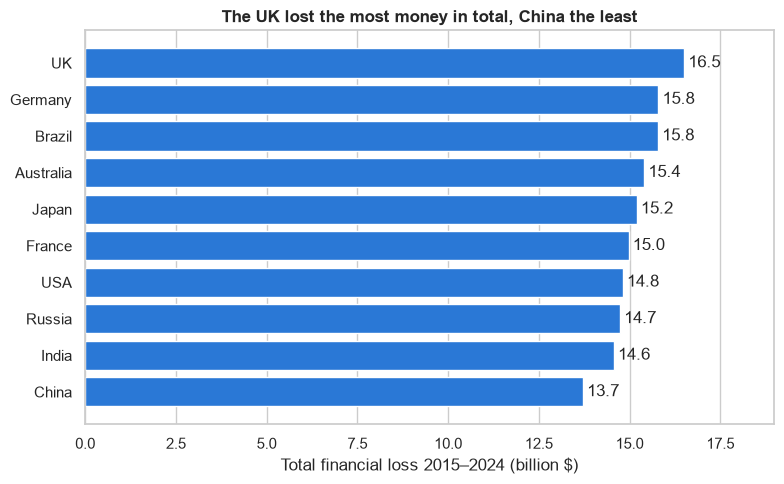

In [27]:
data = by_country.sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(data.index.astype(str), data.values / 1000, color=BLUE)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, data.max() / 1000 * 1.15)
ax.set_title("The UK lost the most money in total, China the least", fontweight="bold")
ax.set_xlabel("Total financial loss 2015–2024 (billion $)")
plt.tight_layout()
plt.savefig("../images/q4_loss_by_country.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** The UK had the highest total loss (16.5B \$) and China the lowest (13.7B \$), a gap of about 20% that partly reflects how many incidents each country recorded.

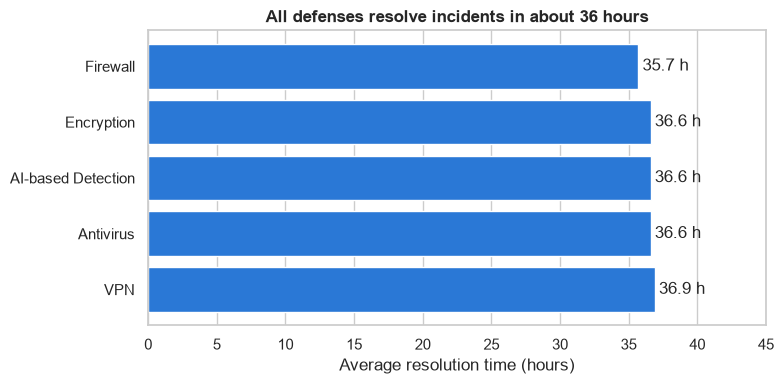

In [28]:
data = by_defense.sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(data.index.astype(str), data["mean"], color=BLUE)
ax.bar_label(bars, fmt="%.1f h", padding=3)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 45)
ax.set_title("All defenses resolve incidents in about 36 hours", fontweight="bold")
ax.set_xlabel("Average resolution time (hours)")
plt.tight_layout()
plt.savefig("../images/q5_defense_resolution.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Average resolution time is about 36 hours for every defense mechanism; Firewall is fastest by only ~1 hour, which is not a meaningful difference.

## 5. Conclusions

### Key Findings
1. **No long-term trend:** Incidents (263–319 per year) and total losses (13.1–16.3B \$ per year) fluctuated between 2015 and 2024 without a clear increase or decrease. Total loss moves with the number of incidents; the average loss per incident stayed around 50M \$.
2. **Attack type barely affects cost:** DDoS was both the most frequent attack (531) and the most costly on average (52.0M \$), but all six attack types fall within 49–52M \$.
3. **Each industry has a different top threat:** Phishing leads in Banking and Retail, DDoS in IT and Telecommunications, Malware in Healthcare, and SQL Injection in Government. IT is the most targeted industry overall (478 incidents).
4. **The UK lost the most:** The UK had the highest total loss (16.5B \$) and China the lowest (13.7B \$).
5. **No defense is clearly faster:** Average resolution time is ~36 hours for every defense mechanism (Firewall 35.7h vs VPN 36.9h).

### Recommendations
- **Prioritize defenses by industry, not by attack cost.** Since losses are similar across attack types, security teams should focus on the attacks most frequent in their own industry (e.g. anti-phishing training for Banking and Retail, DDoS protection for IT and Telecom).
- **Don't rely on a single defense mechanism.** No mechanism showed a meaningful advantage in resolution time, so a layered approach is more sensible than investing in one tool.
- **Improve attribution.** A share of incidents has an "Unknown" attack source; better logging and threat intelligence would make future analysis more useful.

### Limitations
- The dataset appears to be **synthetic**: numeric values are almost uniformly distributed, which is unusual for real incident data. Findings demonstrate the analysis method rather than real-world conclusions.
- Results show **correlation, not causation** (e.g. a defense linked to faster resolution does not prove it causes it).
- Country totals depend on the number of recorded incidents per country, not only on attack severity.

### Next Steps
- Repeat the analysis on a real-world dataset (e.g. the EuRepoC cyber incident database).
- Build an interactive dashboard (Project 2) on the cleaned data in `data/cybersecurity_threats_clean.csv`.